In [ ]:
import pandas as pd
import numpy as np

In [7]:
np.random.seed(42)
n = 2000   # 2000 parts

# ---------- 1. Independent features ----------
material = np.random.choice(["Steel", "Aluminium", "Titanium"],
                            size=n, p=[0.5, 0.3, 0.2])

spindle_speed = np.random.normal(1500, 300, n).clip(600, 2500)
feed_rate     = np.random.normal(200, 40, n).clip(80, 350)
tool_wear     = np.random.uniform(0, 240, n)          # minutes
coolant_flow  = np.random.normal(8, 1.5, n).clip(2, 14)

# ---------- 2. Dependent features (physics logic) ----------
material_heat = pd.Series(material).map(
    {"Aluminium": 0, "Steel": 15, "Titanium": 35}
).values

cutting_temp = (120 + 0.03 * spindle_speed + 0.1 * feed_rate
                + 0.15 * tool_wear - 4 * coolant_flow
                + material_heat + np.random.normal(0, 8, n))

vibration = (0.5 + 0.0008 * spindle_speed + 0.002 * feed_rate
             + 0.008 * tool_wear + np.random.normal(0, 0.3, n)).clip(0.1)

# ---------- 3. Defect probability ----------
def zscore(x):
    return (x - x.mean()) / x.std()

material_risk = pd.Series(material).map(
    {"Aluminium": -0.3, "Steel": 0.0, "Titanium": 0.5}
).values

risk_score = (1.2 * zscore(vibration)
              + 1.0 * zscore(cutting_temp)
              + 0.8 * zscore(tool_wear)
              - 0.5 * zscore(coolant_flow)
              + material_risk)

logit = -2.2 + risk_score
defect_prob = 1 / (1 + np.exp(-logit))        # sigmoid: score → probability (0 to 1)
defect = np.random.binomial(1, defect_prob)   # coin flip with that probability

# ---------- 4. DataFrame ----------
df = pd.DataFrame({
    "part_id": range(1, n + 1),
    "material_type": material,
    "spindle_speed_rpm": spindle_speed.round(0),
    "feed_rate_mm_min": feed_rate.round(1),
    "cutting_temp_c": cutting_temp.round(1),
    "vibration_mm_s": vibration.round(2),
    "tool_wear_min": tool_wear.round(1),
    "coolant_flow_lpm": coolant_flow.round(2),
    "defect": defect
})


In [8]:
# 3% missing values in vibration and coolant (sensor failure)
df.loc[df.sample(frac=0.03, random_state=1).index, "vibration_mm_s"] = np.nan
df.loc[df.sample(frac=0.03, random_state=2).index, "coolant_flow_lpm"] = np.nan

# 20 duplicate rows (data entry mistake)
df = pd.concat([df, df.sample(20, random_state=3)], ignore_index=True)

print("Shape:", df.shape)

Shape: (2020, 9)


In [12]:
df.head()


,part_id,material_type,spindle_speed_rpm,feed_rate_mm_min,cutting_temp_c,vibration_mm_s,tool_wear_min,coolant_flow_lpm,defect
0,1,Steel,1237.0,213.9,203.4,3.90,223.8,7.28,1
1,2,Titanium,1252.0,300.5,204.8,2.93,91.9,7.93,0
2,3,Aluminium,1432.0,126.4,166.7,3.62,175.1,10.01,0
3,4,Aluminium,1610.0,198.7,169.0,2.49,4.9,5.10,0
4,5,Steel,1774.0,225.6,190.6,2.46,49.2,NaN,0


In [13]:
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 2020 entries, 0 to 2019
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   part_id            2020 non-null   int64  
 1   material_type      2020 non-null   str    
 2   spindle_speed_rpm  2020 non-null   float64
 3   feed_rate_mm_min   2020 non-null   float64
 4   cutting_temp_c     2020 non-null   float64
 5   vibration_mm_s     1959 non-null   float64
 6   tool_wear_min      2020 non-null   float64
 7   coolant_flow_lpm   1959 non-null   float64
 8   defect             2020 non-null   int32  
dtypes: float64(6), int32(1), int64(1), str(1)
memory usage: 134.3 KB


(2020, 9)

In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
part_id,2020.0,998.392574,577.260752,1.00,498.750,996.50,1497.25,2000.00
spindle_speed_rpm,2020.0,1502.564356,299.879762,600.00,1303.000,1501.00,1704.00,2500.00
feed_rate_mm_min,2020.0,198.452327,39.501987,80.00,172.075,199.20,225.10,329.70
cutting_temp_c,2020.0,184.431881,21.369674,122.70,169.300,184.20,198.30,260.00
vibration_mm_s,1959.0,3.034247,0.680353,1.07,2.540,3.03,3.54,4.97
tool_wear_min,2020.0,116.283267,68.045979,0.10,58.700,115.65,171.50,239.70
coolant_flow_lpm,1959.0,8.027264,1.530196,2.25,7.020,8.01,9.05,13.07
defect,2020.0,0.252475,0.434540,0.00,0.000,0.00,1.00,1.00


In [19]:
print(df["defect"].value_counts())
print(df["defect"].value_counts(normalize=True) * 100)

defect
0    1510
1     510
Name: count, dtype: int64
defect
0    74.752475
1    25.247525
Name: proportion, dtype: float64


In [20]:
df.to_csv("../data/raw/cnc_machining_data.csv", index=False)
print("Saved ✅")

Saved ✅


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/cnc_machining_data.csv")
print("Original shape:", df.shape)
df.head()

Original shape: (2020, 9)


,part_id,material_type,spindle_speed_rpm,feed_rate_mm_min,cutting_temp_c,vibration_mm_s,tool_wear_min,coolant_flow_lpm,defect
0,1,Steel,1237.0,213.9,203.4,3.90,223.8,7.28,1
1,2,Titanium,1252.0,300.5,204.8,2.93,91.9,7.93,0
2,3,Aluminium,1432.0,126.4,166.7,3.62,175.1,10.01,0
3,4,Aluminium,1610.0,198.7,169.0,2.49,4.9,5.10,0
4,5,Steel,1774.0,225.6,190.6,2.46,49.2,NaN,0


In [9]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("shape after removing dupilcate row", df.shape)

Duplicate rows: 20
shape after removing dupilcate row (2000, 9)


In [11]:
missing = df.isnull().sum()
missing_pct = (df.isnull().mean()*100).round(2)

pd.DataFrame({"missing_count": missing, "missing_%": missing_pct})

,missing_count,missing_%
part_id,0,0.0
material_type,0,0.0
spindle_speed_rpm,0,0.0
feed_rate_mm_min,0,0.0
cutting_temp_c,0,0.0
vibration_mm_s,60,3.0
tool_wear_min,0,0.0
coolant_flow_lpm,60,3.0
defect,0,0.0


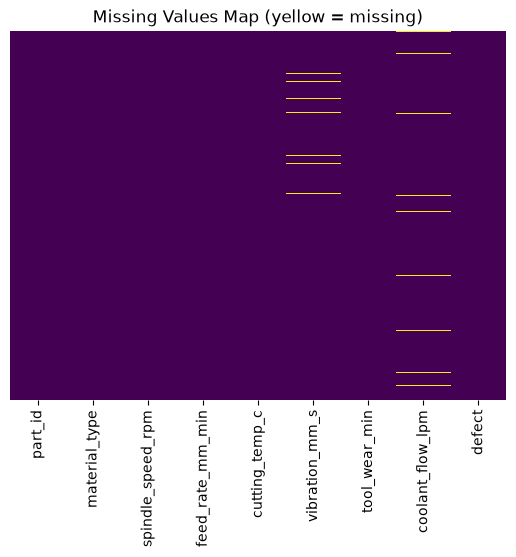

In [17]:
plt.Figure(figsize=(8,4))
sns.heatmap(df.isnull(),
            cbar=False,
            yticklabels=False,
            cmap="viridis")
plt.title("Missing Values Map (yellow = missing)")
plt.show()

In [18]:
for col in ["vibration_mm_s", "coolant_flow_lpm"]:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)
    print(f"{col}: filled with median = {median_value}")

print("\nRemaining missing:", df.isnull().sum().sum())

vibration_mm_s: filled with median = 3.03
coolant_flow_lpm: filled with median = 8.01

Remaining missing: 0


In [22]:
df.dtypes

part_id                int64
material_type            str
spindle_speed_rpm    float64
feed_rate_mm_min     float64
cutting_temp_c       float64
vibration_mm_s       float64
tool_wear_min        float64
coolant_flow_lpm     float64
defect                 int64
dtype: object

Outlier detection

In [23]:
num_cols = ["spindle_speed_rpm", "feed_rate_mm_min", "cutting_temp_c",
            "vibration_mm_s", "tool_wear_min", "coolant_flow_lpm"]

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col:22s} outliers: {n_out:4d}  (limits: {lower:.1f} to {upper:.1f})")

spindle_speed_rpm      outliers:   18  (limits: 701.5 to 2305.5)
feed_rate_mm_min       outliers:   17  (limits: 92.7 to 304.6)
cutting_temp_c         outliers:    8  (limits: 126.3 to 241.2)
vibration_mm_s         outliers:    1  (limits: 1.1 to 5.0)
tool_wear_min          outliers:    0  (limits: -110.9 to 340.9)
coolant_flow_lpm       outliers:   24  (limits: 4.1 to 11.9)


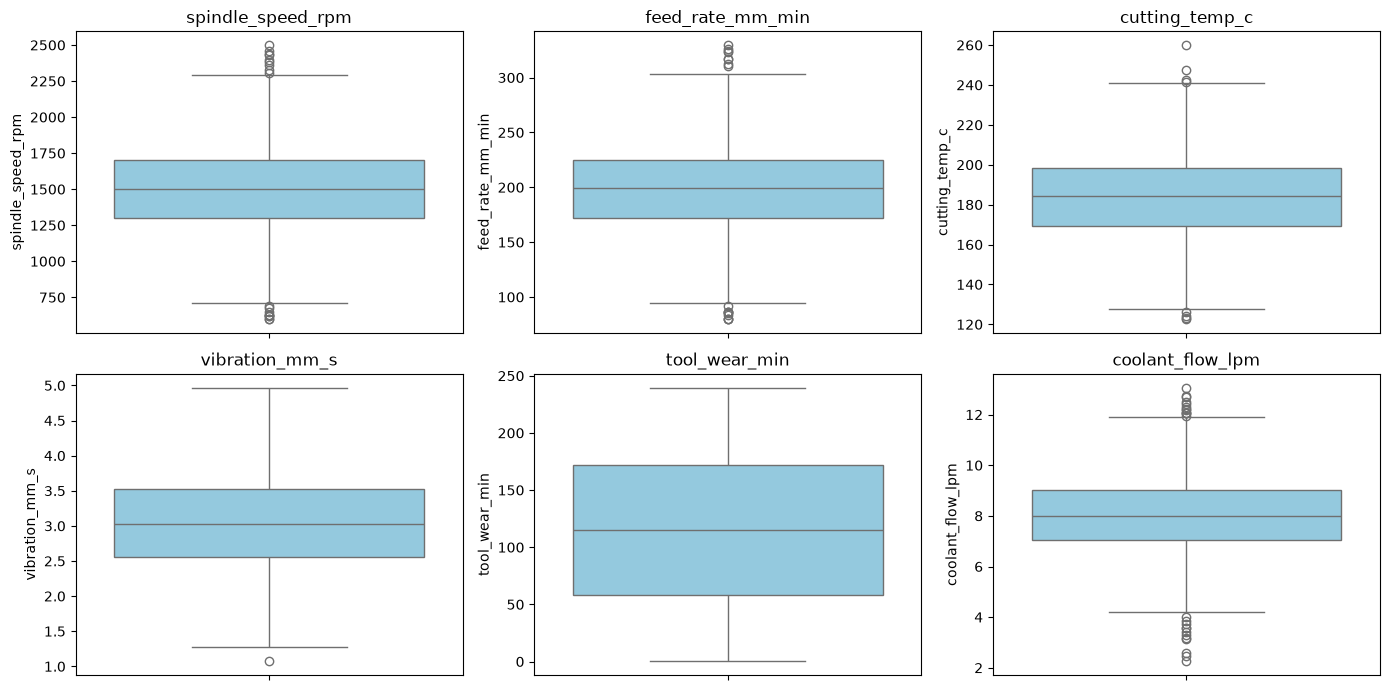

In [ ]:
plt.figure(figsize=(14, 7))

for i, col in enumerate(num_cols):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[col], color="skyblue")
    plt.title(col)

plt.tight_layout()
plt.show()

In [27]:
# Physically impossible values irukka?
checks = {
    "Negative speed":      (df["spindle_speed_rpm"] <= 0).sum(),
    "Negative feed":       (df["feed_rate_mm_min"] <= 0).sum(),
    "Negative tool wear":  (df["tool_wear_min"] < 0).sum(),
    "Negative vibration":  (df["vibration_mm_s"] < 0).sum(),
    "Temp > 500 C":        (df["cutting_temp_c"] > 500).sum(),
    "Invalid defect label":(~df["defect"].isin([0, 1])).sum(),
}
for k, v in checks.items():
    print(f"{k:20s}: {v}")

Negative speed      : 0
Negative feed       : 0
Negative tool wear  : 0
Negative vibration  : 0
Temp > 500 C        : 0
Invalid defect label: 0


In [32]:
df.to_csv("../data/processed/cnc_clean.csv", index=False)
print("Clean data saved ✅  Shape:", df.shape)

Clean data saved ✅  Shape: (2000, 9)
